## Plot 2D slices of the gamma ray, synchrotron, and number densities

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import astropy.units as u
import json

import matplotlib.colors as mcolors
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable

from transform_data import get_transformed_data

import flash_amr_tools
import h5py

In [2]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/emission_revised"
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/updated_outputs"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"

# load the bowshock config
bowshock_config = json.load(open("../../config/bowshock_config.json", "r"))["config"]

In [6]:
sims = ["ISM-v40-MDiff", "ISM-v40-LDiff", "ISM-v40-HDiff", "ISM-v100-MDiff"]
fields = ["gamma_intensity", "synch_intensity"]

times_to_plot = np.array([60, 100, 300, 500])
sim_ids = (times_to_plot // 20).astype(int)
synch_freq = 1.5 # in units of GHz

sim_textlabel = {
    "ISM-v40-LDiff" : (-15, -9.5),
    "ISM-v40-MDiff" : (-15, -9.5),
    "ISM-v40-HDiff" : (-15, -9.5),
    "ISM-v100-MDiff" : (-15, -9.5),
    "ISM-v40-MHD" : (-15, -9.5),
}
field_labels = {
    "ncr" : r"$n_\mathrm{CR, p}$ / cm$^{-3}$",
    "gamma_intensity" : r"Gamma-ray Emissivity $j_\gamma$ / erg s$^{-1}$ cm$^{-3}$",
    "ncre" : r"$\epsilon_\mathrm{CR, e}$ / erg cm$^{-3}$",
    "synch_intensity" : r"Synchrotron Emissivity $j_\mathrm{syn, 1.5GHz}$ / erg s$^{-1}$ cm$^{-3}$"
}

field_cmaps = {
    "ncr" : cm.BuGn_r,
    "ncre" : cm.plasma,
    "gamma_intensity" : cm.RdPu_r,
    "synch_intensity" : cm.cividis
}

field_lims = {
    "ncr" : [1e-15, 1e-7],
    "ncre" : [1e-18, 1e-12],
    "gamma_intensity" : [1e-30, 1e-26],
    "synch_intensity" : [1e-43, 5e-40]
}

In [7]:
def load_file_contents(sim_file, emission_file):
    blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

    pf = h5py.File(sim_file)
    ref_lvl = pf["refine level"][()][blist]
    bbox = pf["bounding box"][()][blist]
    bsize = pf["block size"][()][blist]
    time = (pf['real scalars'][()][0][1] * u.s).to(u.kyr)
    print(time)

    low_cor, up_cor = bbox[0,:,0], bbox[-1,:,1]
    # extent for imshow
    extent = ([low_cor[0], up_cor[0], low_cor[1], up_cor[1]] * u.cm).to_value(u.pc)

    pf.close()

    # read in the emission data file
    emission_hdf5 = h5py.File(emission_file, "r")

    # wrap reader parameters in dictionary
    reader_params = {
        "brefs": brefs,
        "bns": bns,
        "ref_lvl": ref_lvl,
        "bbox": bbox,
        "bsize": bsize,
    }

    return emission_hdf5, reader_params, blist, extent, time

Processing time 60 kyr
Processing simulation ISM-v40-MDiff
minimum position of the region of interest:  [-1.54283879e+20 -7.71419300e+19 -7.71419300e+19]
maximum position of the region of interest:  [1.54283879e+20 7.71419300e+19 7.71419300e+19]
Finding all leaf blocks in given region
2368 2368
Biggest block has refinement level: 4
Highest refinement level in simulation: 6
Highest refinement level in selected box: 6
Extending region to fit amr structure at level 4.
Trying extended region given by including blocks whose center is not in predefined region but part of their block volume is.
bnx, bny, bnz:  16.0 8.0 8.0
Block shape:  (16, 8, 8)
Total number of blocks including parent blocks: 2560
Region extended to:	lower		upper
	x	-1.54283876e+20		+1.54283876e+20
	y	-7.71419293e+19		+7.71419293e+19
	z	-7.71419293e+19		+7.71419293e+19

Region center at:	+0.00000000e+00	+0.00000000e+00	+0.00000000e+00
Given center:		+0.00000000e+00	+0.00000000e+00	+0.00000000e+00
60.02862641067303 kyr
field

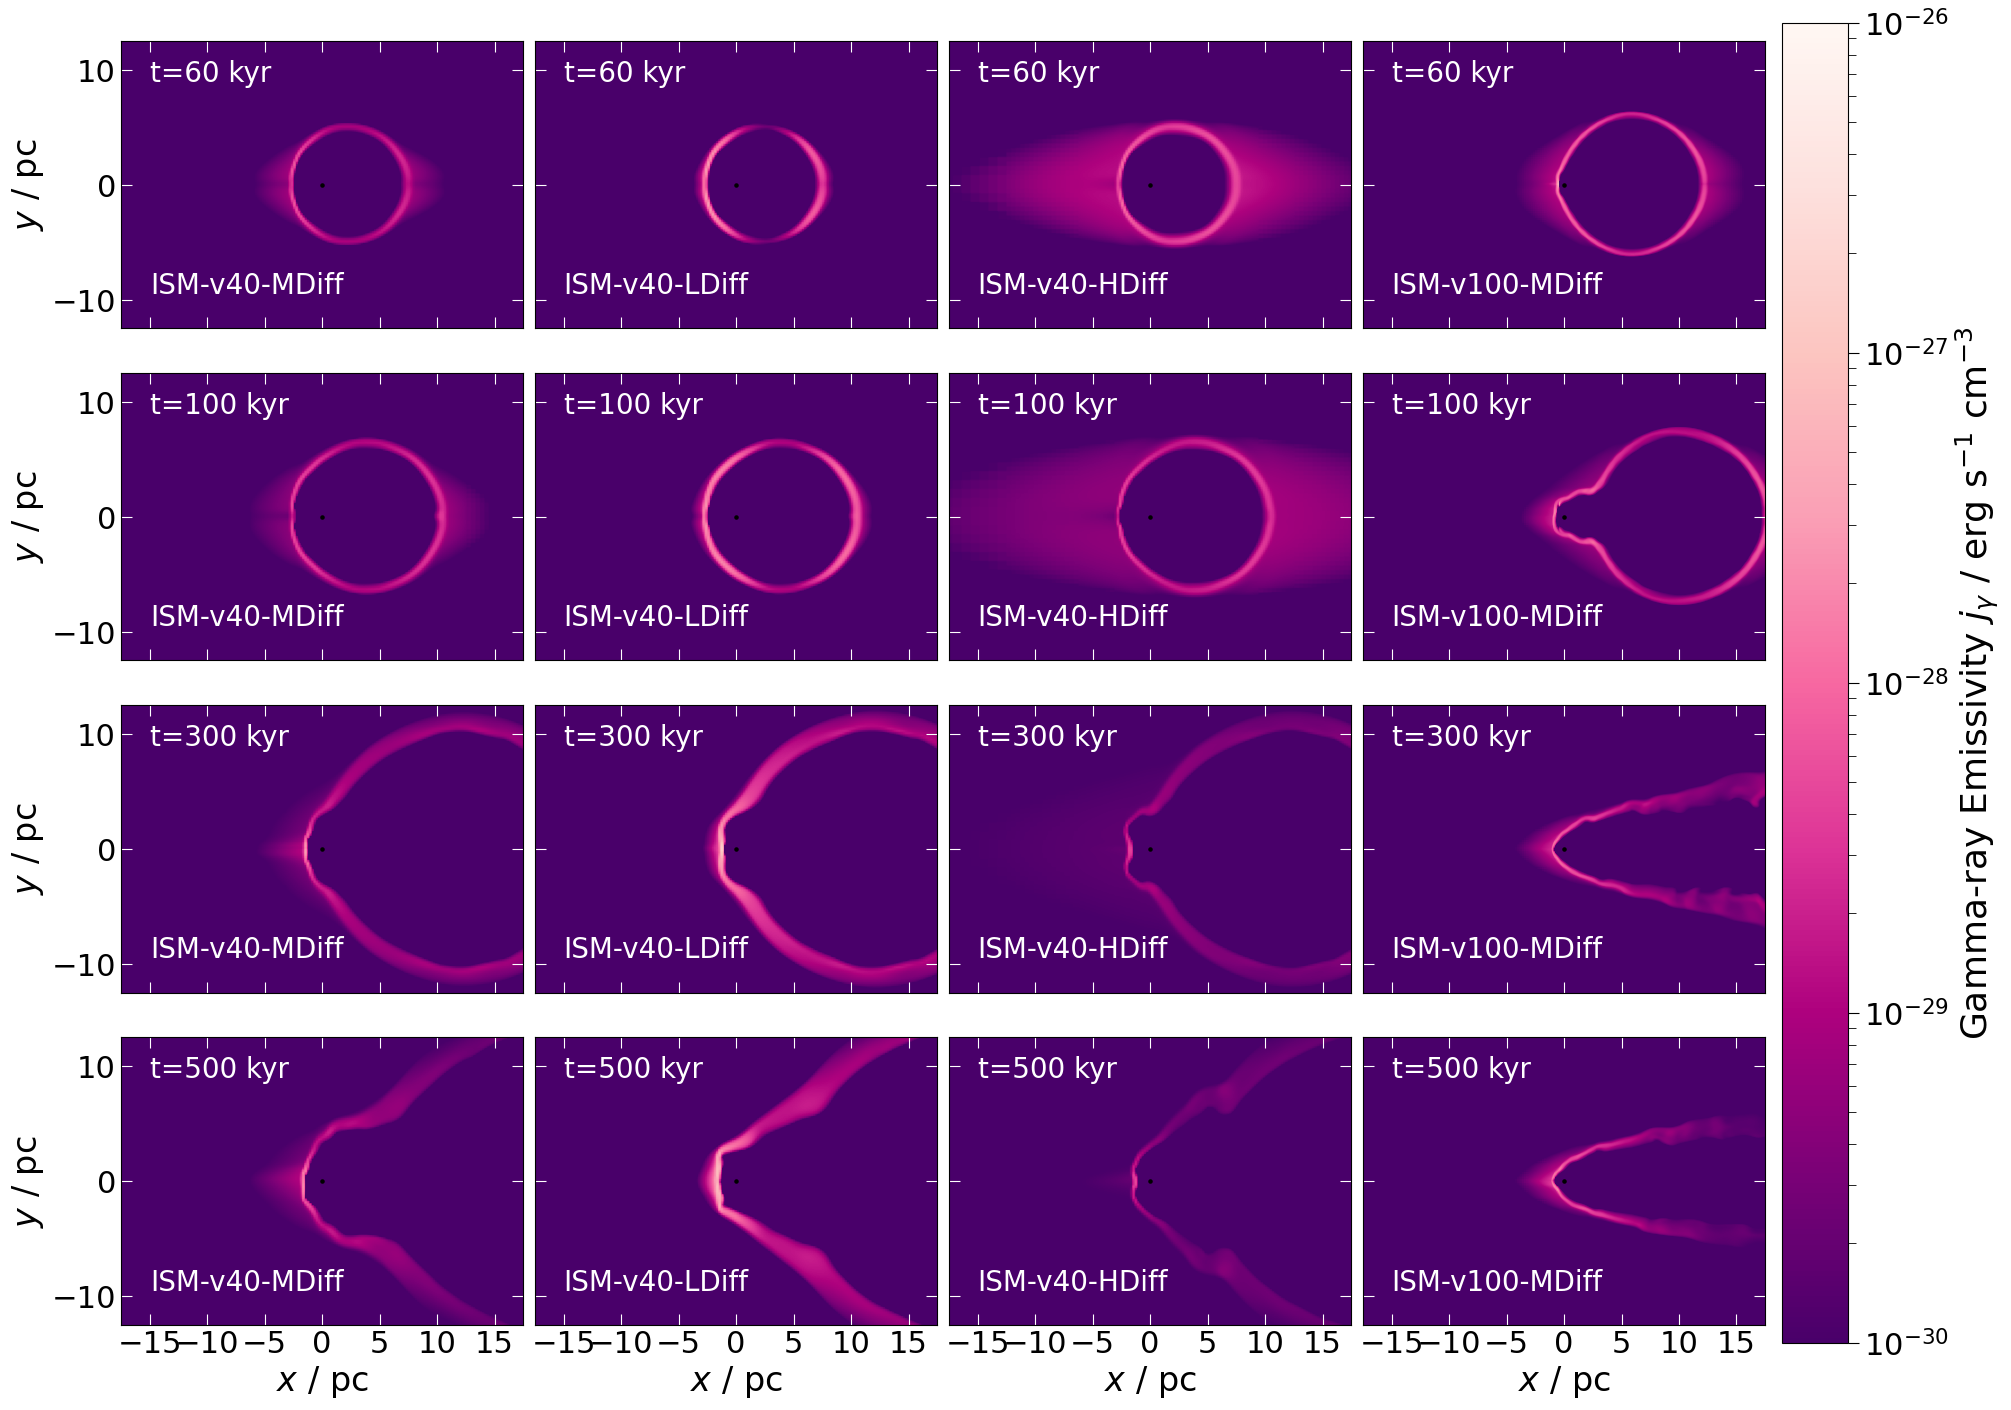

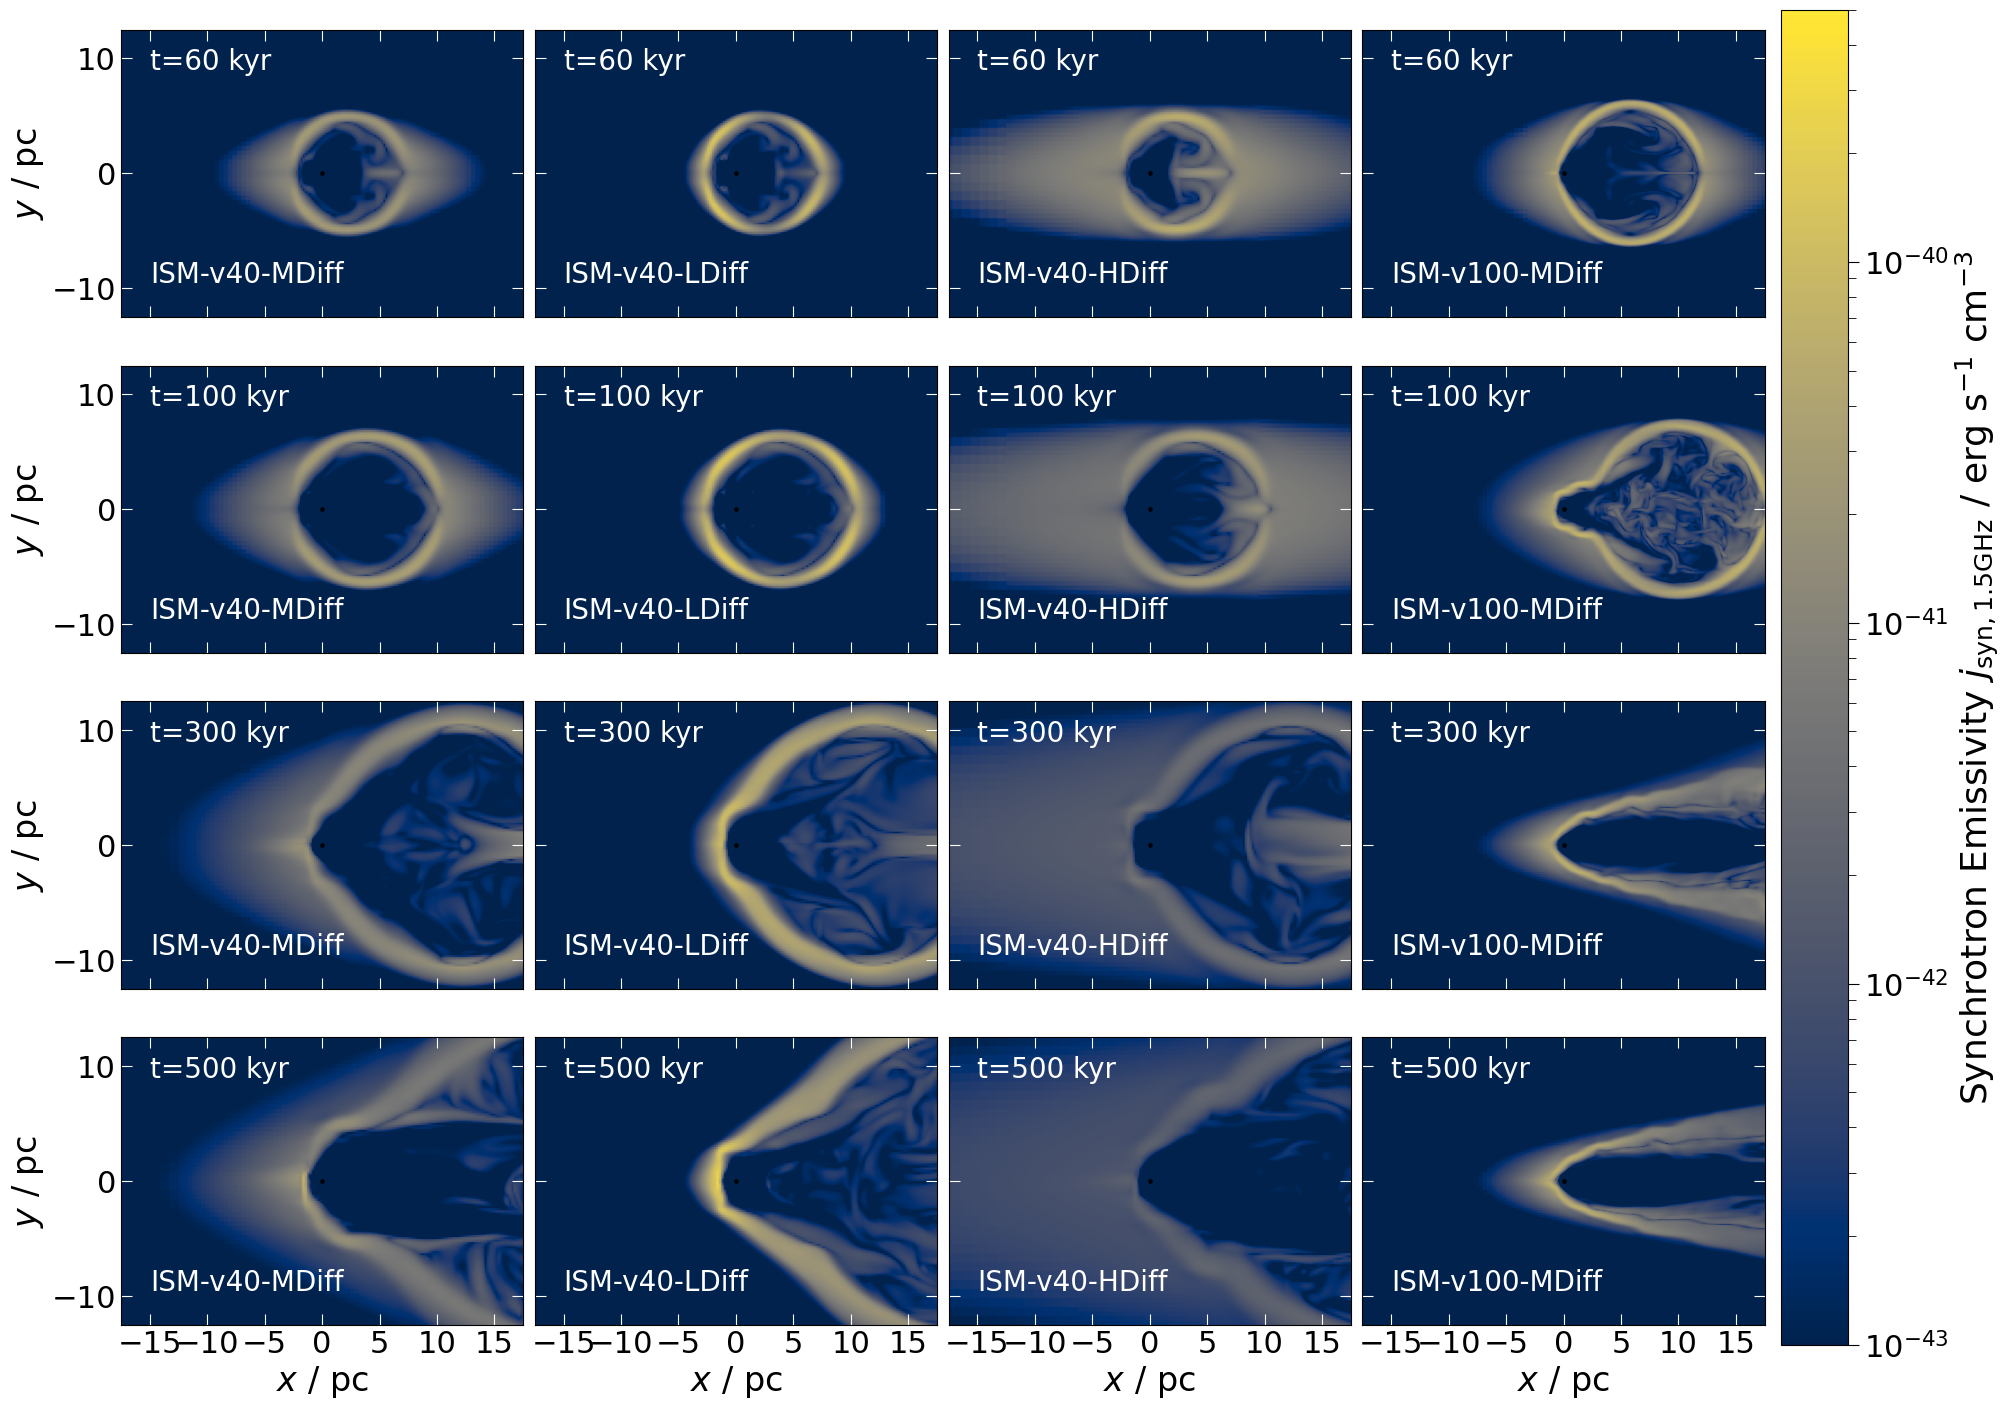

In [8]:
for ifield, field in enumerate(fields):

    fig = plt.figure(figsize=(20,14), constrained_layout=True)
    gs = fig.add_gridspec(len(times_to_plot), len(sims), hspace=0, wspace=0)
    axs = gs.subplots(sharex=True, sharey=True)

    for itime, time in enumerate(times_to_plot):
        print(f"Processing time {time} kyr")
        for isim, sim in enumerate(sims):
            print(f"Processing simulation {sim}")
            # f_label = "ncr" if field.find("ncre") != -1 else field
            # f_label = "synch_alpha42" if field.find("synch") != -1 else field
            f_label = field

            emission_file = os.path.join(flash_output_dir, sim, f"emission_data_t{time:.0f}.h5")
            sim_file = os.path.join(flash_output_dir, sim, f"starISM_hdf5_plt_cnt_{sim_ids[itime]:04d}")

            emission_hdf5, reader_params, blist, extent, _ = load_file_contents(sim_file, emission_file)

            if field.startswith('synch_intensity') or field.startswith('ncre_synch'):
                field_hdf5_label = f'{field}_{synch_freq:.2f}GHz'
            else:
                field_hdf5_label = field
            field_data = np.abs(emission_hdf5[field_hdf5_label][()])
            field_slice = flash_amr_tools.get_slice(field_data, pos=0.0, axis=2, **reader_params)
            print(f"field slice min/max: {field_slice.min()}, {field_slice.max()}")

            # normaliztion for color
            norm = mcolors.LogNorm(vmin=field_lims[field][0], vmax=field_lims[field][1], clip=True)

            im = axs[itime, isim].imshow(field_slice.T, norm=norm, cmap=field_cmaps[field], origin="lower", extent=extent, rasterized=True)
            axs[itime, isim].scatter(0, 0, s=5.0, color="k")

            # limits
            axs[itime, isim].set_xlim(-17.5, 17.5)
            axs[itime, isim].set_ylim(-12.5,12.5)

            # add annotations for the simulation labels
            axs[itime, isim].annotate(f"t={time} kyr", xy=(-15, 9.), color="w", fontsize=20, zorder=100)
            axs[itime, isim].annotate(bowshock_config[sim]["label"], xy=sim_textlabel[sim], color="w", fontsize=20, zorder=100)

            # labels
            if itime == len(times_to_plot) -1:
                axs[itime, isim].set_xlabel("$x$ / pc", fontsize=24)
            if isim == 0 :
                axs[itime, isim].set_ylabel("$y$ / pc", fontsize=24)

            if itime == len(times_to_plot) -1:
                # ticks
                axs[itime, isim].tick_params(axis='x', direction="in", which='major', size=8, labelsize=22, top=True, right=True, color="w")
                axs[itime, isim].tick_params(axis='x', direction="in", which='minor', size=6, labelsize=20, top=True, right=True, color="w")
            else:
                axs[itime, isim].tick_params(axis='x', direction="in", which='major', size=8, labelsize=0, top=True, right=True, color="w")
                axs[itime, isim].tick_params(axis='x', direction="in", which='minor', size=6, labelsize=0, top=True, right=True, color="w")
            if isim == 0:
                axs[itime, isim].tick_params(axis='y', direction="in", which='major', size=8, labelsize=22, top=True, right=True, color="w")
                axs[itime, isim].tick_params(axis='y', direction="in", which='minor', size=6, labelsize=20, top=True, right=True, color="w")
            else:
                # ticks
                axs[itime, isim].tick_params(axis='y', direction="in", which='major', size=8, labelsize=0, top=True, right=True, color="w")
                axs[itime, isim].tick_params(axis='y', direction="in", which='minor', size=6, labelsize=0, top=True, right=True, color="w")
    
    cb = fig.colorbar(im, ax=axs.ravel().tolist(), orientation="vertical", pad=0.01, fraction=0.1)
    cb.ax.set_ylabel(field_labels[field], fontsize=26)
    cb.ax.tick_params(axis='both', which='major', size=8, labelsize=22)
    cb.ax.tick_params(axis='both', which='minor', size=6, labelsize=22)
    cb.ax.set_yscale("log")

    fig.savefig(f"{fig_dir}/2d_slices_{field}_timeevo.pdf", dpi=200, bbox_inches="tight")